In [ ]:
# LSM basic functionality

In [10]:
from quasinet.qnet import Qnet, save_qnet, load_qnet, qdistance, qdistance_matrix, membership_degree
from quasinet.qsampling import qsample
import pandas as pd
import numpy as np

In [4]:
df=pd.read_csv('ptsdALPHnoIndex.txt', keep_default_na=False)
df_training=df.sample(50)
feature_names=df.columns.values
X=df.values.astype('U10')

In [5]:
model = Qnet(n_jobs=11,feature_names=feature_names,alpha=.15)
model.fit(X)
model.training_index=df_training.index.values
save_qnet(model,'model',gz=True)

In [6]:
df_test = df.drop(index=df_training.index).sample(50)
X_test=df_test[model.feature_names].values.astype('U10')

In [8]:
# 1. qdistance calculation
H=qdistance_matrix(X_test,X_test,model,model)

symmetric case


In [24]:
# 2. P_null calculation

NULL = np.array(['']*len(model.feature_names)).astype('U10')
Pnull = model.predict_distributions(NULL)

In [48]:
# 3. omega_s calculation

def omega(s,model):
    Ps = model.predict_distributions(s)
    omega_s = np.array([max(d, key=d.get) for d in Ps])
    return omega_s

# most likely perturbation around a given sample
omega_s = omega(X_test[13],model)

# most likley sample given no information
omega_null = omega(NULL,model)
print(omega_s)
print(omega_null)


['X' 'H' '2' '2' 'M' 'L' 'M' '2' '2' '2' 'L' 'M' 'M' '2' 'M' 'M' '2' 'M'
 'M' 'J' 'L' 'L' 'L' 'L' 'M' 'M' '2' 'J' 'J' '2' '2' '2' '2' '2' '2' 'L'
 'M' 'M' '2' 'M' 'J' '2' 'M' '2' '2' 'L' 'L' 'L' 'M' 'M' 'M' '2' 'M' 'M'
 'L' 'L' 'M' 'M' '2' 'J' 'M' 'H' 'L' 'L' 'L' 'M' 'L' 'L' 'M' 'M' '2' '2'
 '2' '2' '2' '2' '2' 'M' '2' '2' '2' '2' '2' 'L' '2' '2' 'L' '2' 'M' '2'
 'J' 'J' 'M' '2' 'J' 'M' '2' 'M' '2' 'L' 'H' '2' '2' '2' 'H' 'J' 'J' 'J'
 '2' 'J' 'J' '2' 'L' '2' '2' 'L' 'L' 'L' 'L' 'J' 'M' '2' 'L' 'J' 'J' 'J'
 'J' 'M' 'L' 'L' '2' 'J' '2' 'M' 'L' 'L' '2' '2' 'M' 'M' '2' 'M' 'L' 'M'
 'M' 'M' '2' '2' '2' 'L' '2' 'L' 'L' '2' '2' '2' 'M' '2' '2' '2' 'L' 'L'
 'L' '2' 'M' 'M' 'M' 'M' '2' 'M' 'L' 'L' '2' 'L' '2' '2' '2' 'M' 'M' 'M'
 'M' 'L' 'L' 'L' 'L' 'L' 'M' 'L' 'L' 'M' 'L' 'L' '2' '2' '2' '2' '2' 'M'
 'M' '2' '2' '2' '2' '2' '2' '2' '2' 'L' '2' '2' 'H' '2']
['X' 'H' '2' 'L' 'L' 'L' '2' 'L' '2' 'L' 'L' 'M' 'L' 'L' '2' 'L' 'L' 'M'
 'L' 'L' 'L' 'L' 'L' 'L' 'M' 'M' 'L' 'L' 'L' '2' '2' 'L' '2' '2' '

In [31]:
# 4. sample-specific Instability
# If instability is 0, then the sample is a fixed point
def instability(s,model):
    Ps = model.predict_distributions(s)
    omega_s = np.array([max(d, key=d.get) for d in Ps])
    return qdistance(s,omega_s,model,model)
instability(X_test[3],model)

0.09915861209330819

In [ ]:
# 5. qsample calculation
STEPS=100
Xq=np.array([qsample(s,model,STEPS) for s in X_test])

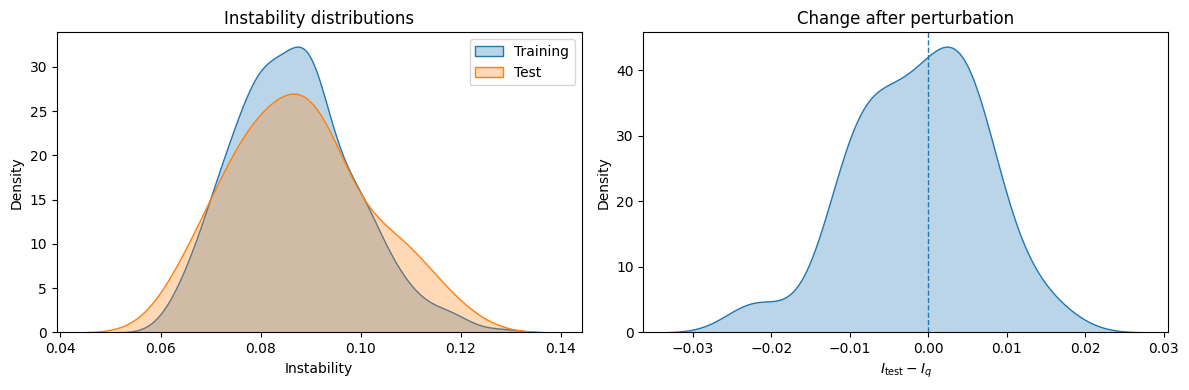

In [38]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

I = np.array([instability(s, model) for s in X])
Itest = np.array([instability(s, model) for s in X_test])
Iq = np.array([instability(s, model) for s in Xq])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Training and test distributions on the same axis
sns.kdeplot(I, ax=axes[0], label="Training", fill=True, alpha=0.3)
sns.kdeplot(Itest, ax=axes[0], label="Test", fill=True, alpha=0.3)

axes[0].set_title("Instability distributions")
axes[0].set_xlabel("Instability")
axes[0].set_ylabel("Density")
axes[0].legend()

# Difference between original test and perturbed test
delta_I = Itest - Iq

sns.kdeplot(delta_I, ax=axes[1], fill=True, alpha=0.3)
axes[1].axvline(0, linestyle="--", linewidth=1)
axes[1].set_title("Change after perturbation")
axes[1].set_xlabel(r"$I_{\mathrm{test}} - I_q$")
axes[1].set_ylabel("Density")

plt.tight_layout()
plt.show()

In [39]:
# 6. persistence probability calculation
def persistence(s,model):
    persistence_prob=0.0
    P=model.predict_distributions(s)
    for i,val in enumerate(s):
        persistence_prob+=np.log10(P[i][val])
    return persistence_prob

persistence(X_test[3],model)

np.float64(-144.45983501167237)

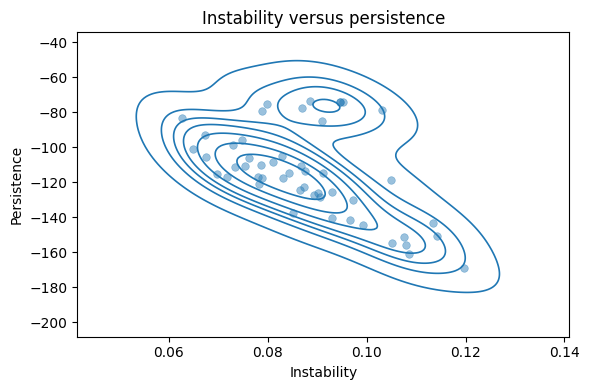

In [50]:
px_test = np.array([persistence(s, model) for s in X_test])

fig, ax = plt.subplots(figsize=(6, 4))
# Individual samples
sns.scatterplot(
    x=Itest,
    y=px_test,
    ax=ax,
    alpha=0.45,
    s=30,
    edgecolor=None
)
# Smoothed two-dimensional density contours
sns.kdeplot(
    x=Itest,
    y=px_test,
    ax=ax,
    levels=8,
    linewidths=1.2
)
ax.set_title("Instability versus persistence")
ax.set_xlabel("Instability")
ax.set_ylabel("Persistence")

plt.tight_layout()
plt.show()